# Per-class test accuracy: before vs after LoRA finetuning

For each architecture (3·3·3, 5·5·5, 9·9·9), compares two models on the **official held-out test set** (`data/cifar-10-batches-py/test_batch`, all 10 classes):

- **Before** — the pretrained Baseline in `saved_models/<arc>/best`: an 8-class (ReLU2) model trained on classes 0–7. It has no output for ship/truck, so those score ~0%.
- **After** — the LoRA-finetuned model in `Done_models/LoRA_with_ReLUNone_arc_(<a_a_a>)/seed*/best`: a 10-class model (relu=2, rank=4) that adapts the frozen Baseline to all 10 classes.

The 'after' checkpoint is a full state_dict (frozen base + LoRA + BN + new head), so we rebuild `QResNetLoRA` and `load_state_dict` directly — no base checkpoint needed. Training may still be running; arches without an 'after' checkpoint yet are shown with the before column only.

Assumes the base models were trained on classes 0–7 (so 8=ship, 9=truck are the held-out pair) and finetuned on all 10 with `--relu 2`.

In [8]:
import os, sys, glob

ROOT = os.getcwd()
if not os.path.exists(os.path.join(ROOT, 'funcs.py')):
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
os.chdir(ROOT)
print('Project root:', ROOT)

import pickle
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from funcs import load_batch
from py_files.Baseline import QResNet, BasicBlock
from py_files.Baseline_with_LoRA import QResNetLoRA, BasicBlockLoRA

Project root: c:\Users\Ali\Desktop\UNI\4\fag\Fagprojekt


In [15]:
# ---- configuration -------------------------------------------------
TRAIN_CLASSES = [0, 1, 2, 3, 4, 5, 6, 7]   # the 8 classes the BASE models were trained on
RELU = 2                                     # base = ReLU2; LoRA finetuned with --relu 2
RANK = 4                                     # LoRA rank used in finetuning (default)

ARCHS = {'3': [3, 3, 3], '5': [5, 5, 5], '9': [9, 9, 9]}
BEFORE_TMPL = 'saved_models/{arc}/best'
AFTER_DIR_TMPL = 'Done_models/LoRA_with_ReLUNone_arc_({arc_str})'  # seed*/best inside

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

with open('data/cifar-10-batches-py/batches.meta', 'rb') as f:
    LABEL_NAMES = [n.decode() for n in pickle.load(f, encoding='bytes')[b'label_names']]
HELD_OUT = [c for c in range(10) if c not in TRAIN_CLASSES]
print('Held-out by base models:', [LABEL_NAMES[c] for c in HELD_OUT])

Device: cuda
Held-out by base models: ['ship', 'truck']


In [16]:
# ---- official test set (all 10 classes), normalised to [0,1] --------
images_test, labels_test = load_batch('data/cifar-10-batches-py/test_batch')
X_test = torch.from_numpy(images_test).float() / 255.0
y_test = torch.from_numpy(labels_test).long().numpy()   # ORIGINAL labels 0..9
print('Test samples:', len(X_test))

Test samples: 10000


In [17]:
# ---- model loaders + evaluation ------------------------------------
TRAIN_CLASSES_ARR = np.array(TRAIN_CLASSES)

def load_before(num_blocks, path):
    """Pretrained Baseline (8-class head, ReLU2)."""
    m = QResNet(RELU, BasicBlock, num_blocks, classes=TRAIN_CLASSES)
    m.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    return m.to(device).eval()

def load_after(num_blocks, path):
    """LoRA-finetuned model (10-class head, relu=2, rank=RANK). The saved file is
    a full state_dict, so just rebuild the module and load it."""
    m = QResNetLoRA(RELU, BasicBlockLoRA, num_blocks, classes=list(range(10)), rank=RANK)
    m.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    return m.to(device).eval()

@torch.no_grad()
def predict(model, X, mapping=None, batch=512):
    """Predicted ORIGINAL class per sample. `mapping` (head index -> original
    class) is used for the 8-class before-model; the after-model's head is already
    in original-class order (classes=range(10)), so mapping=None."""
    out = []
    for i in range(0, len(X), batch):
        idx = model(X[i:i+batch].to(device)).argmax(1).cpu().numpy()
        out.append(mapping[idx] if mapping is not None else idx)
    return np.concatenate(out)

def per_class_acc(pred, y):
    return np.array([100.0 * (pred[y == c] == c).mean() for c in range(10)])

def find_after(num_blocks):
    """Lowest-numbered seed checkpoint for this arch, or None if not finetuned yet."""
    arc_str = '_'.join(map(str, num_blocks))
    cands = sorted(glob.glob(f"{AFTER_DIR_TMPL.format(arc_str=arc_str)}/seed*/best"))
    return cands[0] if cands else None

In [18]:
# ---- evaluate before vs after for every architecture ----------------
tables, overall = {}, {}
for arc, num_blocks in ARCHS.items():
    before = load_before(num_blocks, BEFORE_TMPL.format(arc=arc))
    pred_b = predict(before, X_test, mapping=TRAIN_CLASSES_ARR)
    acc_b = per_class_acc(pred_b, y_test)
    ov_b = 100.0 * (pred_b == y_test).mean()

    after_path = find_after(num_blocks)
    if after_path is not None:
        after = load_after(num_blocks, after_path)
        pred_a = predict(after, X_test)
        acc_a = per_class_acc(pred_a, y_test)
        ov_a = 100.0 * (pred_a == y_test).mean()
        note = f'after: {after_path}'
    else:
        acc_a = np.full(10, np.nan); ov_a = np.nan
        note = 'after: (not finetuned yet)'

    df = pd.DataFrame({'before': acc_b, 'after': acc_a}, index=LABEL_NAMES)
    df['delta'] = df['after'] - df['before']
    df.loc['— OVERALL —'] = [ov_b, ov_a, ov_a - ov_b]
    tables[arc] = df.round(2)
    overall[arc] = (ov_b, ov_a)
    print(f"arc {arc} ({'-'.join(map(str, num_blocks))})  overall  before {ov_b:.2f}%  "
          f"after {ov_a:.2f}%   | {note}")

arc 3 (3-3-3)  overall  before 64.80%  after 80.51%   | after: Done_models/LoRA_with_ReLUNone_arc_(3_3_3)\seed0\best
arc 5 (5-5-5)  overall  before 66.04%  after 76.27%   | after: Done_models/LoRA_with_ReLUNone_arc_(5_5_5)\seed0\best
arc 9 (9-9-9)  overall  before 66.19%  after nan%   | after: (not finetuned yet)


In [19]:
# ---- per-architecture before/after/delta tables ---------------------
for arc, df in tables.items():
    print(f"\n=== arc {arc} ({'-'.join(map(str, ARCHS[arc]))}) ===")
    display(df)


=== arc 3 (3-3-3) ===


,before,after,delta
airplane,90.4,79.80,-10.60
automobile,96.5,88.30,-8.20
bird,70.4,73.30,2.90
cat,69.7,69.10,-0.60
deer,77.7,79.50,1.80
dog,74.5,74.60,0.10
frog,86.0,85.40,-0.60
horse,82.8,85.50,2.70
ship,0.0,84.90,84.90
truck,0.0,84.70,84.70



=== arc 5 (5-5-5) ===


,before,after,delta
airplane,88.80,78.00,-10.80
automobile,96.80,80.50,-16.30
bird,69.60,76.20,6.60
cat,67.50,66.00,-1.50
deer,85.20,82.30,-2.90
dog,76.30,76.00,-0.30
frog,89.90,86.60,-3.30
horse,86.30,87.00,0.70
ship,0.00,58.60,58.60
truck,0.00,71.50,71.50



=== arc 9 (9-9-9) ===


,before,after,delta
airplane,90.40,NaN,NaN
automobile,97.10,NaN,NaN
bird,74.90,NaN,NaN
cat,67.10,NaN,NaN
deer,79.90,NaN,NaN
dog,76.80,NaN,NaN
frog,89.20,NaN,NaN
horse,86.50,NaN,NaN
ship,0.00,NaN,NaN
truck,0.00,NaN,NaN


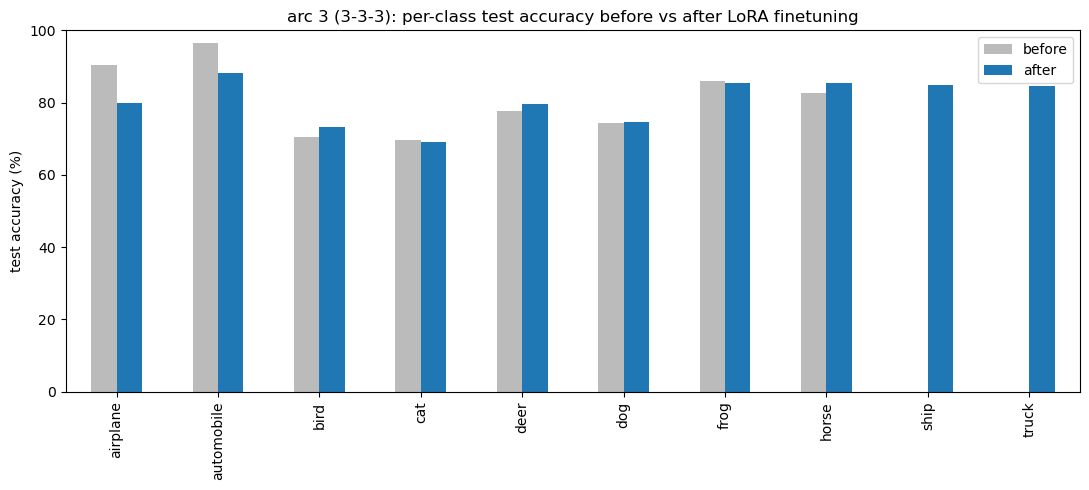

In [20]:
# ---- bar chart: before vs after, per class (first finetuned arch) ----
import matplotlib.pyplot as plt

arc = next((a for a, (b, af) in overall.items() if not np.isnan(af)), None)
if arc is None:
    print('No finetuned (after) model available yet to plot.')
else:
    df = tables[arc].drop(index='— OVERALL —')[['before', 'after']]
    ax = df.plot.bar(figsize=(11, 5), color=['#bbbbbb', '#1f77b4'])
    ax.set_ylabel('test accuracy (%)'); ax.set_ylim(0, 100)
    ax.set_title(f"arc {arc} ({'-'.join(map(str, ARCHS[arc]))}): per-class test accuracy before vs after LoRA finetuning")
    ax.legend(title=None)
    plt.tight_layout(); plt.show()